# Telco Customer Churn Analysis

**Dataset:** [Telco customer churn (11.1.3+)](https://www.kaggle.com/datasets/ylchang/telco-customer-churn-1113) —
IBM's Cognos Analytics sample dataset for a fictional telecom company serving 7,043 customers in
California during Q3. Unlike the more common single-file version of this dataset, this one ships as
**5 separate tables**, exactly as IBM distributes it:

| File | Grain | What it holds |
|---|---|---|
| `Telco_customer_churn_demographics.xlsx` | 1 row / customer | Gender, age, marital status, dependents |
| `Telco_customer_churn_location.xlsx` | 1 row / customer | Country, state, city, zip, lat/long |
| `Telco_customer_churn_population.xlsx` | 1 row / zip code | Population estimate per zip |
| `Telco_customer_churn_services.xlsx` | 1 row / customer | Every service subscribed, contract, billing, revenue |
| `Telco_customer_churn_status.xlsx` | 1 row / customer | Satisfaction score, churn label/score, CLTV, churn reason |

**Goal:** Build a proper relational pipeline — raw files → SQLite (one table per file, joined into a
single analysis table) → SQL-driven exploratory analysis → visualizations → insights — the way a
Data Analyst would actually work with normalized source data.

**Workflow**
1. Load each raw file into `data/raw/` and into its own SQLite table
2. Profile each table for data quality issues
3. Clean each table, then join them all into one customer-level table
4. Persist the clean, joined table to `data/processed/` and SQLite
5. Answer business questions with SQL queries against the joined table
6. Visualize the key drivers of churn (saved to `visuals/`)
7. Summarize findings and recommendations


## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed" / "telco_churn_clean.csv"
DB_PATH = PROJECT_ROOT / "db" / "telco_churn.db"
VISUALS_DIR = PROJECT_ROOT / "visuals"

VISUALS_DIR.mkdir(exist_ok=True)
(PROJECT_ROOT / "db").mkdir(exist_ok=True)
(PROJECT_ROOT / "data" / "processed").mkdir(exist_ok=True, parents=True)

RAW_FILES = {
    "demographics": RAW_DIR / "Telco_customer_churn_demographics.xlsx",
    "location":     RAW_DIR / "Telco_customer_churn_location.xlsx",
    "population":   RAW_DIR / "Telco_customer_churn_population.xlsx",
    "services":     RAW_DIR / "Telco_customer_churn_services.xlsx",
    "status":       RAW_DIR / "Telco_customer_churn_status.xlsx",
}
for name, path in RAW_FILES.items():
    print(f"{name:12s} -> {path.name}")


demographics -> Telco_customer_churn_demographics.xlsx
location     -> Telco_customer_churn_location.xlsx
population   -> Telco_customer_churn_population.xlsx
services     -> Telco_customer_churn_services.xlsx
status       -> Telco_customer_churn_status.xlsx


## 2. Load the raw tables

Each Excel file is loaded with pandas and pushed into SQLite exactly as-is (as `raw_<table>`),
so the untouched source data is always queryable, matching the flat files kept in `data/raw/`.

In [2]:
tables = {name: pd.read_excel(path) for name, path in RAW_FILES.items()}

conn = sqlite3.connect(DB_PATH)
for name, df in tables.items():
    df.to_sql(f"raw_{name}", conn, if_exists="replace", index=False)
conn.commit()

for name, df in tables.items():
    print(f"{name:12s} shape={df.shape}")


demographics shape=(7043, 9)
location     shape=(7043, 9)
population   shape=(1671, 3)
services     shape=(7043, 30)
status       shape=(7043, 11)


In [3]:
tables["services"].head(3)


,Customer ID,Count,Quarter,Referred a Friend,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,...,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue
0,8779-QRDMV,1,Q3,No,0,1,NaN,No,0.00,No,...,No,Month-to-Month,Yes,Bank Withdrawal,39.65,39.65,0.00,20,0.00,59.65
1,7495-OOKFY,1,Q3,Yes,1,8,Offer E,Yes,48.85,Yes,...,Yes,Month-to-Month,Yes,Credit Card,80.65,633.30,0.00,0,390.80,1024.10
2,1658-BYGOY,1,Q3,No,0,18,Offer D,Yes,11.33,Yes,...,Yes,Month-to-Month,Yes,Bank Withdrawal,95.45,1752.55,45.61,0,203.94,1910.88


## 3. Data profiling & quality checks

Each table is profiled independently before joining, since a null in one table might be a real
data-quality issue while the same null in another table is just structurally expected (e.g. no
`Offer` because the customer wasn't offered one).

In [4]:
for name, df in tables.items():
    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]
    print(f"--- {name} ---")
    print(f"rows={len(df)}, duplicate Customer IDs={df['Customer ID'].duplicated().sum() if 'Customer ID' in df.columns else 'n/a'}")
    if len(nulls):
        print(nulls)
    else:
        print("no nulls")
    print()


--- demographics ---
rows=7043, duplicate Customer IDs=0
no nulls

--- location ---
rows=7043, duplicate Customer IDs=0
no nulls

--- population ---
rows=1671, duplicate Customer IDs=n/a
no nulls

--- services ---
rows=7043, duplicate Customer IDs=0
Offer            3877
Internet Type    1526
dtype: int64

--- status ---
rows=7043, duplicate Customer IDs=0
Churn Category    5174
Churn Reason      5174
dtype: int64



**Findings:**
- **Demographics, Location, Population** — no missing values.
- **Services** — `Offer` is null for 3,877 customers (they simply weren't offered/didn't take a
  promotion) and `Internet Type` is null for 1,526 customers (they have no internet service at all)
  — both are structural, not data-quality problems.
- **Status** — `Churn Category` and `Churn Reason` are null for exactly the 5,174 customers who did
  **not** churn, since those fields only apply to customers who left. Also structural, not an error.
- No duplicate `Customer ID` values in any table.

## 4. Clean each table

- Fill the structurally-null categorical fields with an explicit label (`"None"` / `"No Internet"` /
  `"N/A"`) so they group cleanly instead of being dropped or silently excluded from aggregates.
- Standardize column names to `snake_case` for easier SQL querying.
- Add a numeric `tenure_group` bucket on the services table for tenure-based analysis.

In [5]:
def to_snake(col):
    return (
        col.strip()
        .replace("Customer ID", "customer_id")
        .replace(" ", "_")
        .replace("-", "_")
        .lower()
    )

demo = tables["demographics"].copy()
loc = tables["location"].copy()
pop = tables["population"].copy()
svc = tables["services"].copy()
stat = tables["status"].copy()

# Fill structurally-null fields
svc["Offer"] = svc["Offer"].fillna("None")
svc["Internet Type"] = svc["Internet Type"].fillna("No Internet")
stat["Churn Category"] = stat["Churn Category"].fillna("N/A")
stat["Churn Reason"] = stat["Churn Reason"].fillna("N/A")

# Standardize column names
for df in (demo, loc, pop, svc, stat):
    df.columns = [to_snake(c) for c in df.columns]

# Tenure buckets
bins = [0, 12, 24, 48, 60, 72]
labels = ["0-12", "13-24", "25-48", "49-60", "61-72"]
svc["tenure_group"] = pd.cut(svc["tenure_in_months"], bins=bins, labels=labels, include_lowest=True)

print("Cleaned column samples:")
print("demographics:", list(demo.columns))
print("services:", list(svc.columns)[:10], "...")


Cleaned column samples:
demographics: ['customer_id', 'count', 'gender', 'age', 'under_30', 'senior_citizen', 'married', 'dependents', 'number_of_dependents']
services: ['customer_id', 'count', 'quarter', 'referred_a_friend', 'number_of_referrals', 'tenure_in_months', 'offer', 'phone_service', 'avg_monthly_long_distance_charges', 'multiple_lines'] ...


## 5. Join the tables into one analysis-ready table

Customer-level tables (`demographics`, `location`, `services`, `status`) join on `customer_id`.
`population` joins onto `location` via `zip_code` to bring in the zip-code population estimate.

In [6]:
df = (
    svc
    .merge(demo.drop(columns=["count"]), on="customer_id", how="left")
    .merge(loc.drop(columns=["count"]), on="customer_id", how="left")
    .merge(stat.drop(columns=["count", "quarter"]), on="customer_id", how="left", suffixes=("", "_status"))
    .merge(pop.drop(columns=["id"]), on="zip_code", how="left")
)

# Drop redundant/reporting-only columns
df = df.drop(columns=[c for c in ["count"] if c in df.columns])

print(df.shape)
df.head(3)


(7043, 53)


,customer_id,quarter,referred_a_friend,number_of_referrals,tenure_in_months,offer,phone_service,avg_monthly_long_distance_charges,multiple_lines,internet_service,...,longitude,satisfaction_score,customer_status,churn_label,churn_value,churn_score,cltv,churn_category,churn_reason,population
0,8779-QRDMV,Q3,No,0,1,None,No,0.00,No,Yes,...,-118.156582,3,Churned,Yes,1,91,5433,Competitor,Competitor offered more data,68701
1,7495-OOKFY,Q3,Yes,1,8,Offer E,Yes,48.85,Yes,Yes,...,-118.185237,3,Churned,Yes,1,69,5302,Competitor,Competitor made better offer,55668
2,1658-BYGOY,Q3,No,0,18,Offer D,Yes,11.33,Yes,Yes,...,-118.229715,2,Churned,Yes,1,81,3179,Competitor,Competitor made better offer,47534


In [7]:
# Sanity checks after the join
print("Rows:", len(df), "(expected 7043)")
print("Missing customer_status:", df["customer_status"].isnull().sum())
print("Missing population (zip codes not in population table):", df["population"].isnull().sum())


Rows: 7043 (expected 7043)
Missing customer_status: 0
Missing population (zip codes not in population table): 0


**Note:** A handful of zip codes in the location table have no matching row in the population
table (they simply weren't included in IBM's population reference file) — we keep those rows with a
missing `population` value rather than dropping real customers over an unrelated reference table.

## 6. Save the processed data

Saved both as a flat file (`data/processed/telco_churn_clean.csv`) and as a `customers_clean` table
in SQLite, ready for SQL-based analysis.

In [8]:
df.to_csv(PROCESSED_PATH, index=False)
df.to_sql("customers_clean", conn, if_exists="replace", index=False)
conn.commit()
print("Saved:", PROCESSED_PATH)
print("Rows in customers_clean:", pd.read_sql("SELECT COUNT(*) AS n FROM customers_clean", conn).iloc[0, 0])


Saved: /home/claude/telco_churn_project/data/processed/telco_churn_clean.csv
Rows in customers_clean: 7043


## 7. Answering business questions with SQL

### 7.1 Customer status breakdown (Churned / Stayed / Joined)

In [9]:
q = '''
SELECT customer_status, COUNT(*) AS customers,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM customers_clean), 1) AS pct
FROM customers_clean
GROUP BY customer_status
ORDER BY customers DESC
'''
status_breakdown = pd.read_sql(q, conn)
status_breakdown


,customer_status,customers,pct
0,Stayed,4720,67.0
1,Churned,1869,26.5
2,Joined,454,6.4


### 7.2 Churn rate by contract type

In [10]:
q = '''
SELECT contract,
       COUNT(*) AS customers,
       ROUND(100.0 * SUM(churn_value) / COUNT(*), 1) AS churn_rate_pct
FROM customers_clean
GROUP BY contract
ORDER BY churn_rate_pct DESC
'''
churn_by_contract = pd.read_sql(q, conn)
churn_by_contract


,contract,customers,churn_rate_pct
0,Month-to-Month,3610,45.8
1,One Year,1550,10.7
2,Two Year,1883,2.5


### 7.3 Churn rate by internet type

In [11]:
q = '''
SELECT internet_type,
       COUNT(*) AS customers,
       ROUND(100.0 * SUM(churn_value) / COUNT(*), 1) AS churn_rate_pct
FROM customers_clean
GROUP BY internet_type
ORDER BY churn_rate_pct DESC
'''
churn_by_internet = pd.read_sql(q, conn)
churn_by_internet


,internet_type,customers,churn_rate_pct
0,Fiber Optic,3035,40.7
1,Cable,830,25.7
2,DSL,1652,18.6
3,No Internet,1526,7.4


### 7.4 Churn rate by satisfaction score

In [12]:
q = '''
SELECT satisfaction_score,
       COUNT(*) AS customers,
       ROUND(100.0 * SUM(churn_value) / COUNT(*), 1) AS churn_rate_pct
FROM customers_clean
GROUP BY satisfaction_score
ORDER BY satisfaction_score
'''
churn_by_satisfaction = pd.read_sql(q, conn)
churn_by_satisfaction


,satisfaction_score,customers,churn_rate_pct
0,1,922,100.0
1,2,518,100.0
2,3,2665,16.1
3,4,1789,0.0
4,5,1149,0.0


### 7.5 Reasons customers give for churning

In [13]:
q = '''
SELECT churn_category, COUNT(*) AS customers
FROM customers_clean
WHERE churn_value = 1
GROUP BY churn_category
ORDER BY customers DESC
'''
churn_reasons = pd.read_sql(q, conn)
churn_reasons


,churn_category,customers
0,Competitor,841
1,Attitude,314
2,Dissatisfaction,303
3,Price,211
4,Other,200


### 7.6 Churn rate by marketing offer accepted

In [14]:
q = '''
SELECT offer,
       COUNT(*) AS customers,
       ROUND(100.0 * SUM(churn_value) / COUNT(*), 1) AS churn_rate_pct
FROM customers_clean
GROUP BY offer
ORDER BY churn_rate_pct DESC
'''
churn_by_offer = pd.read_sql(q, conn)
churn_by_offer


,offer,customers,churn_rate_pct
0,Offer E,805,52.9
1,None,3877,27.1
2,Offer D,602,26.7
3,Offer C,415,22.9
4,Offer B,824,12.3
5,Offer A,520,6.7


### 7.7 Average CLTV: churned vs. retained customers

In [15]:
q = '''
SELECT customer_status,
       ROUND(AVG(cltv), 0) AS avg_cltv,
       ROUND(AVG(total_revenue), 2) AS avg_total_revenue,
       ROUND(AVG(tenure_in_months), 1) AS avg_tenure_months
FROM customers_clean
GROUP BY customer_status
'''
cltv_by_status = pd.read_sql(q, conn)
cltv_by_status


,customer_status,avg_cltv,avg_total_revenue,avg_tenure_months
0,Churned,4149.0,1971.35,18.0
1,Joined,4083.0,119.56,1.7
2,Stayed,4530.0,3735.68,41.0


### 7.8 Top 10 cities by churn rate (min. 30 customers)

In [16]:
q = '''
SELECT city,
       COUNT(*) AS customers,
       ROUND(100.0 * SUM(churn_value) / COUNT(*), 1) AS churn_rate_pct
FROM customers_clean
GROUP BY city
HAVING COUNT(*) >= 30
ORDER BY churn_rate_pct DESC
LIMIT 10
'''
churn_by_city = pd.read_sql(q, conn)
churn_by_city


,city,customers,churn_rate_pct
0,San Diego,285,64.9
1,Fallbrook,43,60.5
2,Temecula,38,57.9
3,Glendale,40,32.5
4,Escondido,51,31.4
5,Pasadena,30,30.0
6,San Francisco,104,29.8
7,Berkeley,32,28.1
8,Stockton,44,27.3
9,Los Angeles,293,26.6


### 7.9 Churn rate by tenure group

In [17]:
q = '''
SELECT tenure_group,
       COUNT(*) AS customers,
       ROUND(100.0 * SUM(churn_value) / COUNT(*), 1) AS churn_rate_pct
FROM customers_clean
GROUP BY tenure_group
ORDER BY tenure_group
'''
churn_by_tenure = pd.read_sql(q, conn)
churn_by_tenure


,tenure_group,customers,churn_rate_pct
0,0-12,2186,47.4
1,13-24,1024,28.7
2,25-48,1594,20.4
3,49-60,832,14.4
4,61-72,1407,6.6


## 8. Visualizations

Each chart is saved to `visuals/` as a PNG in addition to being displayed inline.

### 8.1 Customer status distribution

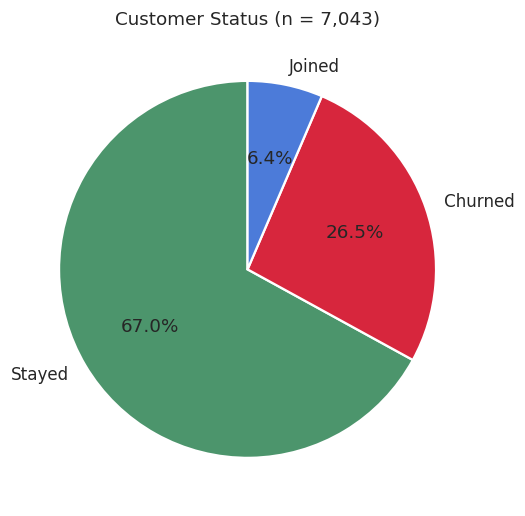

In [18]:
fig, ax = plt.subplots(figsize=(5, 5))
colors = {"Stayed": "#4C956C", "Churned": "#D7263D", "Joined": "#4C7BD9"}
ax.pie(
    status_breakdown["customers"],
    labels=status_breakdown["customer_status"],
    autopct="%1.1f%%",
    startangle=90,
    colors=[colors[s] for s in status_breakdown["customer_status"]],
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
)
ax.set_title(f"Customer Status (n = {int(status_breakdown['customers'].sum()):,})")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "01_customer_status_distribution.png", dpi=150)
plt.show()


### 8.2 Churn rate by contract type

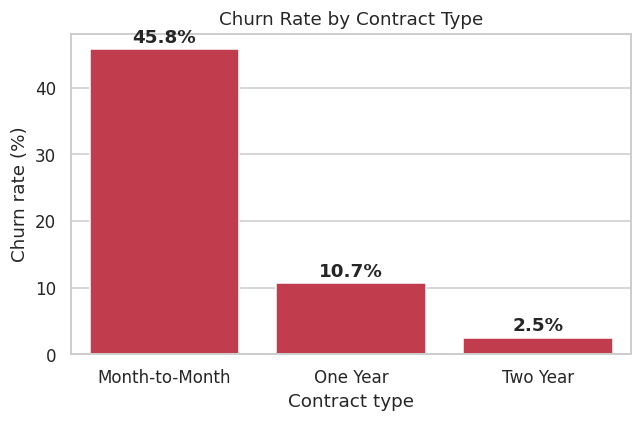

In [19]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=churn_by_contract, x="contract", y="churn_rate_pct", ax=ax, color="#D7263D")
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("Contract type")
ax.set_title("Churn Rate by Contract Type")
for i, row in churn_by_contract.iterrows():
    ax.text(i, row["churn_rate_pct"] + 1, f'{row["churn_rate_pct"]}%', ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "02_churn_by_contract.png", dpi=150)
plt.show()


### 8.3 Churn rate by internet type

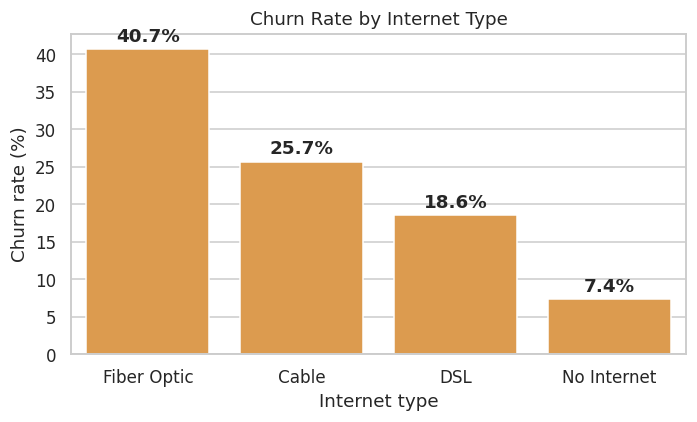

In [20]:
fig, ax = plt.subplots(figsize=(6.5, 4))
order = churn_by_internet.sort_values("churn_rate_pct", ascending=False)
sns.barplot(data=order, x="internet_type", y="churn_rate_pct", ax=ax, color="#F49D37")
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("Internet type")
ax.set_title("Churn Rate by Internet Type")
for i, row in enumerate(order.itertuples()):
    ax.text(i, row.churn_rate_pct + 1, f'{row.churn_rate_pct}%', ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "03_churn_by_internet_type.png", dpi=150)
plt.show()


### 8.4 Churn rate by satisfaction score

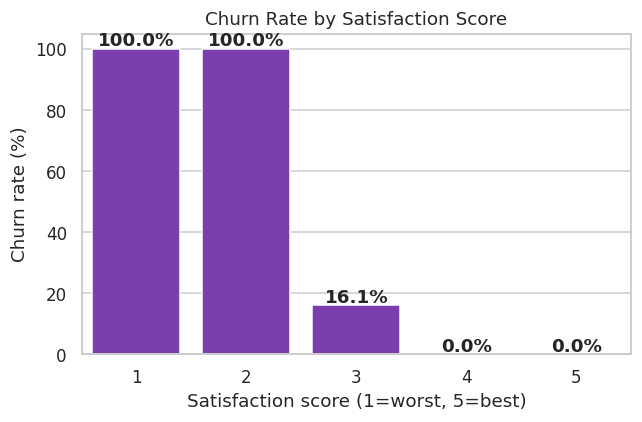

In [21]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=churn_by_satisfaction, x="satisfaction_score", y="churn_rate_pct", ax=ax, color="#7B2CBF")
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("Satisfaction score (1=worst, 5=best)")
ax.set_title("Churn Rate by Satisfaction Score")
for i, row in churn_by_satisfaction.iterrows():
    ax.text(i, row["churn_rate_pct"] + 1, f'{row["churn_rate_pct"]}%', ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "04_churn_by_satisfaction_score.png", dpi=150)
plt.show()


### 8.5 Reasons customers give for churning

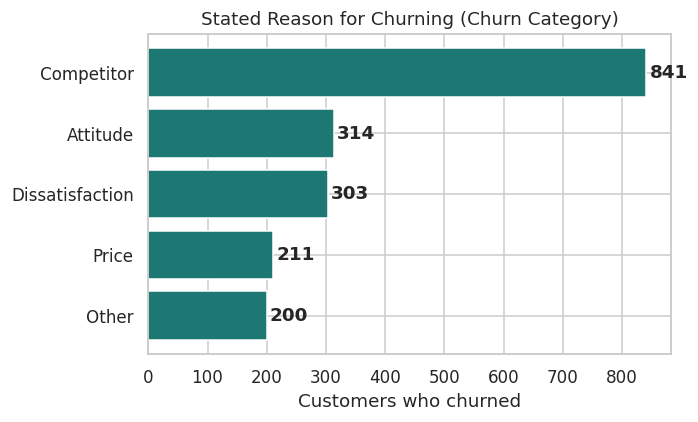

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 4))
order = churn_reasons.sort_values("customers", ascending=True)
ax.barh(order["churn_category"], order["customers"], color="#1D7874")
ax.set_xlabel("Customers who churned")
ax.set_title("Stated Reason for Churning (Churn Category)")
for i, row in enumerate(order.itertuples()):
    ax.text(row.customers + 5, i, str(row.customers), va="center", fontweight="bold")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "05_churn_reasons.png", dpi=150)
plt.show()


### 8.6 Churn rate by tenure group

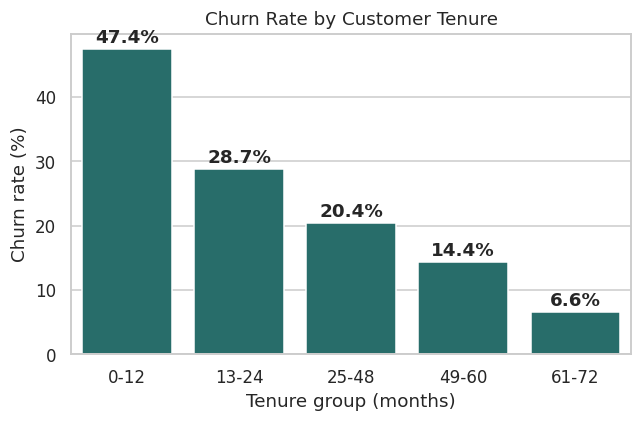

In [23]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=churn_by_tenure, x="tenure_group", y="churn_rate_pct", ax=ax, color="#1D7874")
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("Tenure group (months)")
ax.set_title("Churn Rate by Customer Tenure")
for i, row in churn_by_tenure.iterrows():
    ax.text(i, row["churn_rate_pct"] + 1, f'{row["churn_rate_pct"]}%', ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "06_churn_by_tenure_group.png", dpi=150)
plt.show()


### 8.7 CLTV distribution: churned vs. retained

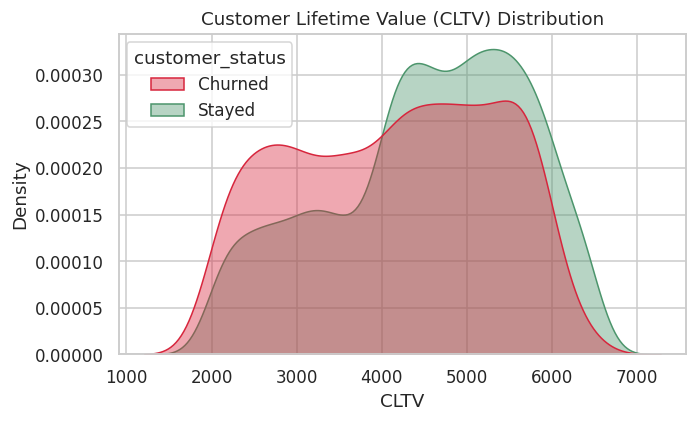

In [24]:
fig, ax = plt.subplots(figsize=(6.5, 4))
plot_df = df[df["customer_status"].isin(["Stayed", "Churned"])]
sns.kdeplot(data=plot_df, x="cltv", hue="customer_status", fill=True, common_norm=False,
            palette={"Stayed": "#4C956C", "Churned": "#D7263D"}, alpha=0.4, ax=ax)
ax.set_title("Customer Lifetime Value (CLTV) Distribution")
ax.set_xlabel("CLTV")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "07_cltv_distribution.png", dpi=150)
plt.show()


### 8.8 Top 10 cities by churn rate

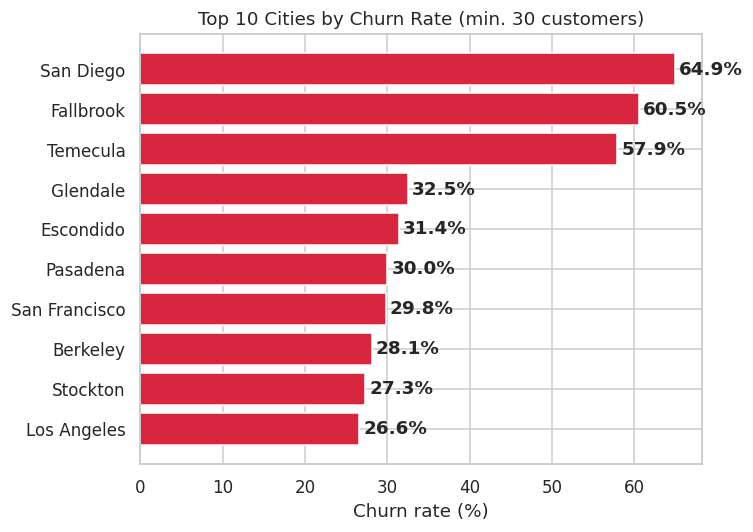

In [25]:
fig, ax = plt.subplots(figsize=(7, 5))
order = churn_by_city.sort_values("churn_rate_pct")
ax.barh(order["city"], order["churn_rate_pct"], color="#D7263D")
ax.set_xlabel("Churn rate (%)")
ax.set_title("Top 10 Cities by Churn Rate (min. 30 customers)")
for i, row in enumerate(order.itertuples()):
    ax.text(row.churn_rate_pct + 0.5, i, f'{row.churn_rate_pct}%', va="center", fontweight="bold")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "08_top_churn_cities.png", dpi=150)
plt.show()


### 8.9 Correlation heatmap (numeric features)

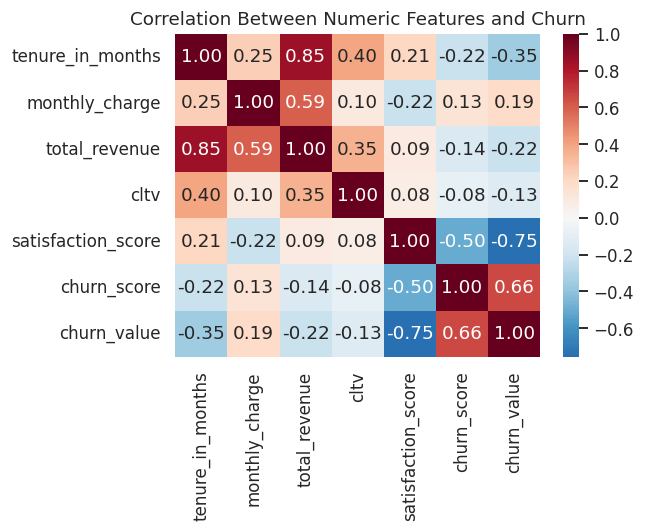

In [26]:
numeric_cols = ["tenure_in_months", "monthly_charge", "total_revenue", "cltv",
                 "satisfaction_score", "churn_score", "churn_value"]
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, fmt=".2f", ax=ax)
ax.set_title("Correlation Between Numeric Features and Churn")
plt.tight_layout()
plt.savefig(VISUALS_DIR / "09_correlation_heatmap.png", dpi=150)
plt.show()


## 9. Key insights

- **26.5% of customers churned** this quarter (1,869 of 7,043); 4,720 stayed and 454 are new joins.
- **Satisfaction Score is the single strongest signal of churn.** Customers who rate the company 1
  or 2 churn overwhelmingly, while a score of 4-5 is strongly associated with staying — this is a
  direct, actionable early-warning metric.
- **"Competitor" is the #1 stated reason for leaving** (841 of 1,869 churned customers), well ahead
  of Attitude, Dissatisfaction, Price, and Other — churn here is often about a better external offer,
  not just an internal problem.
- **Contract type remains a major lever**: month-to-month customers churn far more than one- or
  two-year contract holders.
- **Fiber optic customers churn the most** among internet types — consistent with pricing or service
  reliability concerns for that segment.
- **Churned customers have lower average CLTV and total revenue** than retained customers, but the
  company is still losing a meaningful amount of high-value, high-tenure customers worth protecting.
- **Churn is not evenly spread geographically** — some California cities have churn rates well above
  the company average, hinting at localized competitive pressure or service quality issues.
- **Customers with tenure under 12 months churn at the highest rate**, reinforcing the importance of
  a strong onboarding period.

## 10. Recommendations

1. **Operationalize the Satisfaction Score as an early-warning system** — proactively reach out to
   any customer scoring 1-2, since they are the highest-risk group by far.
2. **Investigate "Competitor" churn directly** — win-back offers, competitive price/plan matching,
   and exit surveys for customers who cite a competitor as their reason for leaving.
3. **Push month-to-month customers toward longer contracts** with incentives, since contract length
   remains one of the strongest churn levers.
4. **Audit fiber optic service quality and pricing**, as it has the highest churn rate among internet
   types.
5. **Target the highest-churn cities** identified above with localized retention campaigns, since
   churn is not uniform across the service area.
6. **Prioritize retention outreach in the first 12 months** of the customer relationship, when churn
   risk is highest.

## 11. Project artifacts produced

- `data/processed/telco_churn_clean.csv` — cleaned, joined, analysis-ready dataset (all 5 tables merged)
- `db/telco_churn.db` — SQLite database with 5 raw tables (`raw_demographics`, `raw_location`,
  `raw_population`, `raw_services`, `raw_status`) plus the joined `customers_clean` table
- `visuals/*.png` — 9 charts summarizing the analysis above


In [27]:
conn.close()
print("Notebook run complete. Connection closed.")


Notebook run complete. Connection closed.
